<a href="https://colab.research.google.com/github/Deyv0R/repo1/blob/main/%D0%9B%D0%A06_%D0%9A%D0%B8%D1%8F%D0%BD%D0%B8%D1%86%D1%8F__4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [3]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [4]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [6]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [7]:
df.info()
# Датасет містить 100 000 рядків та 9 колонок.
# Типи даних: float64 (age, bmi, HbA1c_level), int64 (hypertension, heart_disease, blood_glucose_level, diabetes),
# object (gender, smoking_history). Пропущених значень (NaN) на перший погляд немає.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [8]:
print(df['gender'].value_counts())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [9]:
print(df['smoking_history'].value_counts())

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [10]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [11]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [12]:
print(df['diabetes'].value_counts())
print("\nЧастка класів:\n", df['diabetes'].value_counts(normalize=True))

diabetes
0    91500
1     8500
Name: count, dtype: int64

Частка класів:
 diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


Висновок: Спостерігається суттєвий дисбаланс класів: близько 91.5% спостережень належать до класу 0 (немає діабету) і лише ~8.5% — до класу 1 (наявність діабету).

Перевірити наявність пропущених даних


In [13]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [14]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [15]:
df.drop_duplicates(inplace=True)
print("Розмір після видалення дублікатів:", df.shape)

Розмір після видалення дублікатів: (96146, 9)


In [18]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [25]:
print(df['diabetes'].value_counts())
print("\nЧастка класів:\n", df['diabetes'].value_counts(normalize=True))

diabetes
0    87664
1     8482
Name: count, dtype: int64

Частка класів:
 diabetes
0    0.91178
1    0.08822
Name: proportion, dtype: float64


Побудувати гістограму для цільової змінної


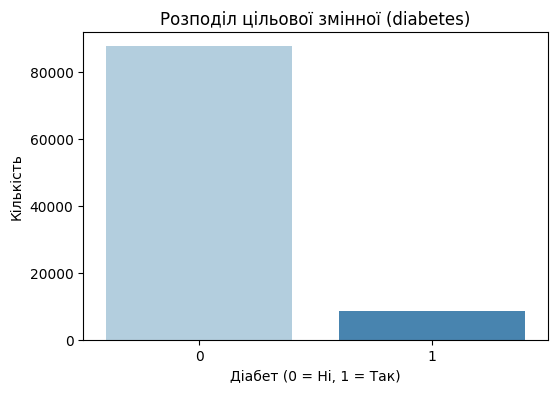

In [26]:
plt.figure(figsize=(6, 4))
sns.countplot(x='diabetes', data=df, hue='diabetes', palette='Blues', legend=False)
plt.title("Розподіл цільової змінної (diabetes)")
plt.xlabel("Діабет (0 = Ні, 1 = Так)")
plt.ylabel("Кількість")
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [21]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [27]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (76916, 8), X_test shape: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [28]:
cat_cols = ['gender', 'smoking_history']
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [29]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_current,76916.0,0.095546,0.293969,0.00,0.00,0.00,0.00,1.00
smoking_history_ever,76916.0,0.041175,0.198696,0.00,0.00,0.00,0.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [30]:
train_corr_y = X_train.apply(lambda col: col.corr(y_train))
print("Кореляція ознак з цільовою змінною:")
print(train_corr_y.sort_values(ascending=False))

Кореляція ознак з цільовою змінною:
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
dtype: float64


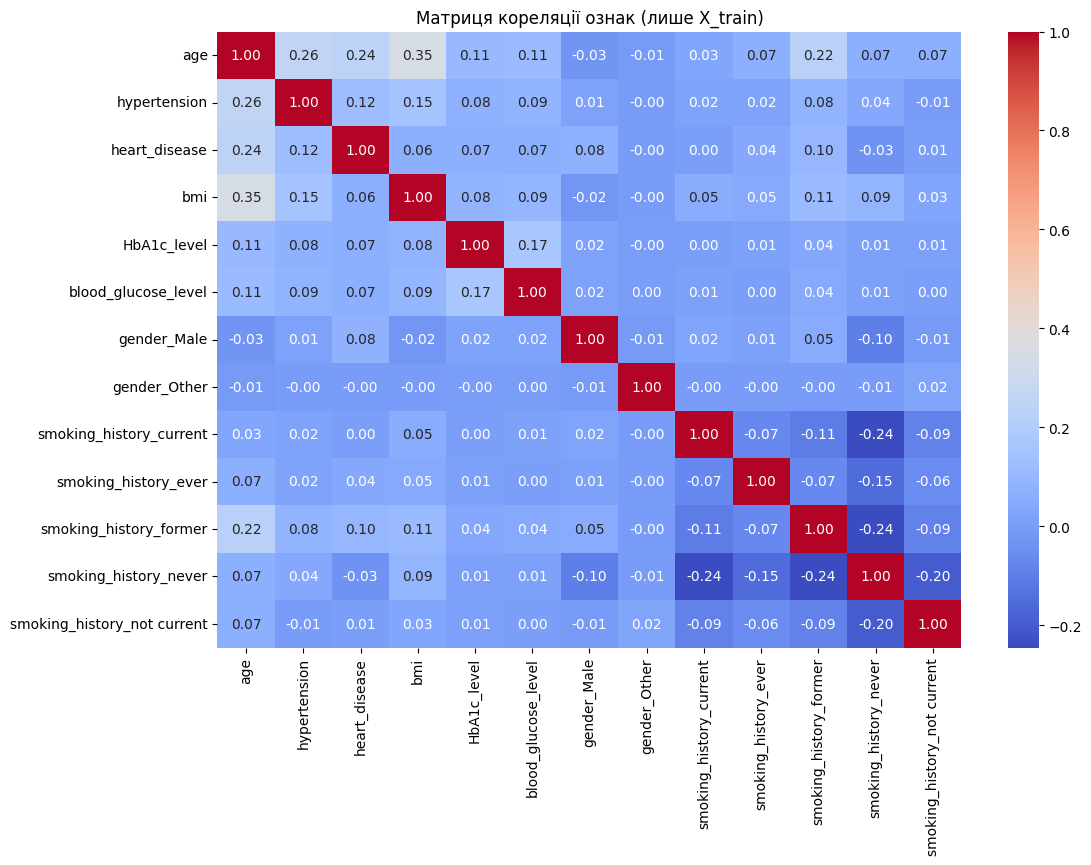

In [31]:
plt.figure(figsize=(12, 8))
corr_matrix = X_train.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Матриця кореляції ознак (лише X_train)")
plt.show()

**Висновок:** Найвищу позитивну лінійну кореляцію з цільовою змінною мають blood_glucose_level ($\approx$ 0.42) та HbA1c_level ($\approx$ 0.40), а також помірну кореляцію показують age та bmi. Ознаки між собою не демонструють надвисокої мультиколінеарності ( |r| > 0.85 відсутня). Видаляти ознаки немає необхідності, оскільки кожна зберігає корисний сигнал для моделей.

Перевірити викиди **лише на навчальній вибірці**

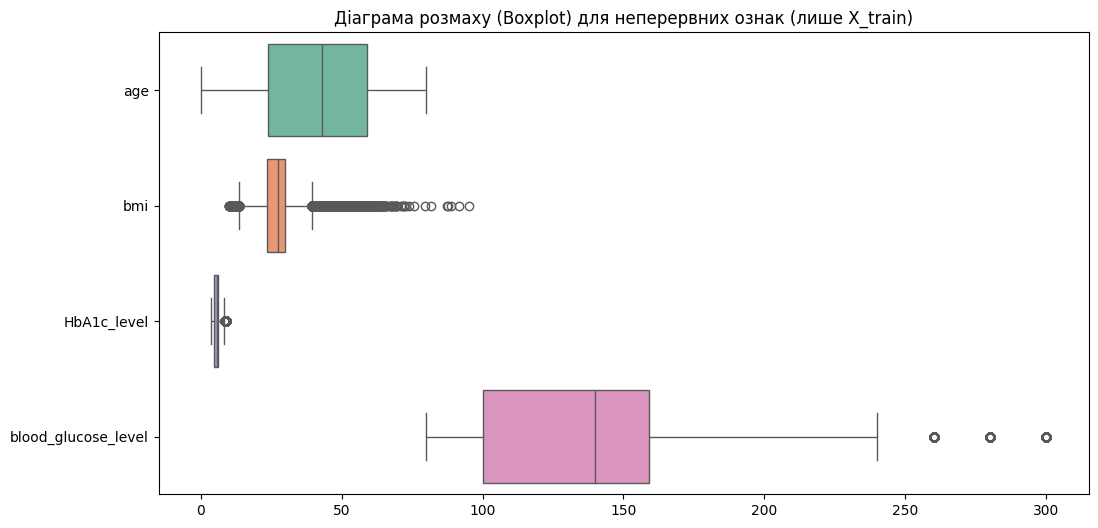

In [34]:
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols], orient='h', palette='Set2')
plt.title("Діаграма розмаху (Boxplot) для неперервних ознак (лише X_train)")
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [35]:
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"bmi bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")

bmi bounds: [13.70, 39.54]


Перевірити асиметрію розподілів ознак **на train**

In [36]:
skewness = X_train[continuous_cols].skew()
print("Асиметрія неперервних ознак:")
print(skewness)

Асиметрія неперервних ознак:
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [37]:
print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_test:", X_test.isnull().sum().sum())

Пропуски в X_train: 0
Пропуски в X_test: 0


**Проміжний висновок:** Спостерігається дисбаланс класів (~1:10 на користь класу 0). Ознаки цукру в крові та глікованого гемоглобіну мають найбільший лінійний зв'язок із діабетом. На графіках розмаху зафіксовано статистичні викиди в bmi та blood_glucose_level.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [38]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [39]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("Розподіл класів до SMOTE:\n", y_train.value_counts())
print("\nРозподіл класів після SMOTE:\n", y_train_resampled.value_counts())

Розподіл класів до SMOTE:
 diabetes
0    70130
1     6786
Name: count, dtype: int64

Розподіл класів після SMOTE:
 diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [40]:
models = {
    "LogisticRegression": LogisticRegression(random_state=42, max_iter=1000),
    "RidgeClassifier": RidgeClassifier(random_state=42),
    "SGDClassifier": SGDClassifier(random_state=42, loss='log_loss'),
    "SVC": SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


=== LogisticRegression ===
Classification Report:
              precision    recall  f1-score   support

           0     0.9870    0.8856    0.9335     17534
           1     0.4264    0.8791    0.5742      1696

    accuracy                         0.8850     19230
   macro avg     0.7067    0.8824    0.7539     19230
weighted avg     0.9375    0.8850    0.9018     19230



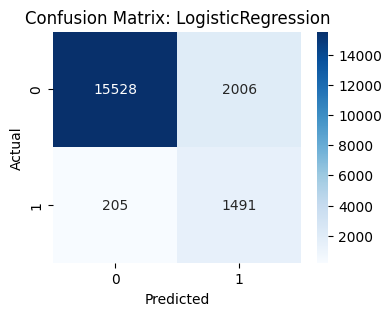

--------------------------------------------------
=== RidgeClassifier ===
Classification Report:
              precision    recall  f1-score   support

           0     0.9866    0.8890    0.9352     17534
           1     0.4325    0.8750    0.5789      1696

    accuracy                         0.8877     19230
   macro avg     0.7096    0.8820    0.7571     19230
weighted avg     0.9377    0.8877    0.9038     19230



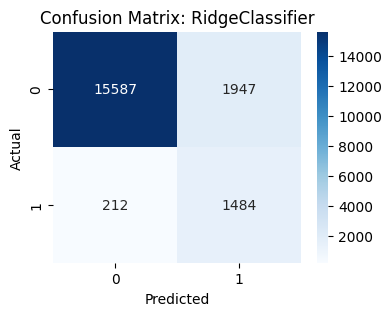

--------------------------------------------------
=== SGDClassifier ===
Classification Report:
              precision    recall  f1-score   support

           0     0.9866    0.8841    0.9326     17534
           1     0.4224    0.8762    0.5700      1696

    accuracy                         0.8834     19230
   macro avg     0.7045    0.8801    0.7513     19230
weighted avg     0.9369    0.8834    0.9006     19230



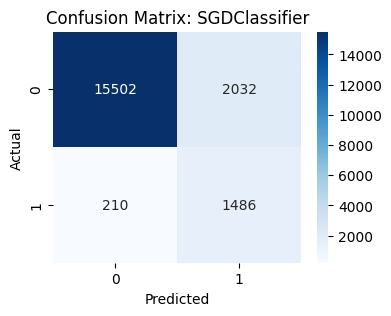

--------------------------------------------------
=== SVC ===
Classification Report:
              precision    recall  f1-score   support

           0     0.9901    0.8810    0.9323     17534
           1     0.4248    0.9086    0.5789      1696

    accuracy                         0.8834     19230
   macro avg     0.7074    0.8948    0.7556     19230
weighted avg     0.9402    0.8834    0.9012     19230



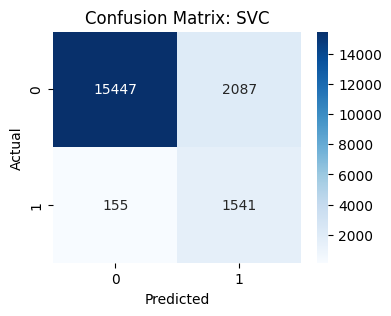

--------------------------------------------------


In [41]:
for name, model in models.items():
    print(f"=== {name} ===")
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)

    print("Classification Report:")
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    print("-" * 50)

Оптимізувати гіперпараметри


In [42]:
param_grids = {
    "LogisticRegression": {
        'model__C': [0.01, 0.1, 1, 10],
        'model__solver': ['lbfgs', 'liblinear']
    },
    "RidgeClassifier": {
        'model__alpha': [0.1, 1.0, 10.0, 50.0]
    },
    "SGDClassifier": {
        'model__loss': ['log_loss', 'hinge', 'modified_huber'],
        'model__penalty': ['l2', 'l1'],
        'model__alpha': [1e-4, 1e-3, 1e-2]
    },
    "SVC": {
        'model__C': [0.5, 1, 5],
        'model__kernel': ['rbf', 'linear']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [43]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [44]:
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"--- Оптимізація для {name} ---")

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print(f"Кращі параметри: {search.best_params_}")
    print(f"Кращий CV F1-score: {search.best_score_:.4f}")

    y_pred = search.best_estimator_.predict(X_test)
    print("Classification Report на тесті:")
    print(classification_report(y_test, y_pred, digits=4))
    print("=" * 60)

--- Оптимізація для LogisticRegression ---
Кращі параметри: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Кращий CV F1-score: 0.6864
Classification Report на тесті:
              precision    recall  f1-score   support

           0     0.9871    0.8855    0.9336     17534
           1     0.4266    0.8803    0.5747      1696

    accuracy                         0.8851     19230
   macro avg     0.7068    0.8829    0.7541     19230
weighted avg     0.9377    0.8851    0.9019     19230

--- Оптимізація для RidgeClassifier ---
Кращі параметри: {'model__alpha': 50.0}
Кращий CV F1-score: 0.6677
Classification Report на тесті:
              precision    recall  f1-score   support

           0     0.9866    0.8890    0.9352     17534
           1     0.4325    0.8750    0.5789      1696

    accuracy                         0.8877     19230
   macro avg     0.7096    0.8820    0.7571     19230
weighted avg     0.9377    0.8877    0.9038     19230

--- Оптимізація для SGDClassifier ---
Кращі

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [45]:
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print(f"Найкраща модель за кросвалідацією: {best_model_name}")
print(f"Середній CV F1-score: {best_scores[best_model_name]:.4f}")

Найкраща модель за кросвалідацією: LogisticRegression
Середній CV F1-score: 0.6864


In [46]:
np.random.seed(42)
sample_indices = np.random.choice(X_test.index, size=10, replace=False)

sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_y_pred = best_model.predict(sample_X)

comparison_df = pd.DataFrame({
    'Index': sample_indices,
    'True_Class': sample_y_true.values,
    'Predicted_Class': sample_y_pred
})

print(comparison_df.to_string(index=False))

 Index  True_Class  Predicted_Class
 36061           0                0
 29824           0                0
 29668           0                1
 11816           0                0
 99242           0                0
 26718           0                0
 53059           0                0
 69294           0                0
  8912           0                1
 37072           0                0


**Підсумкові висновки (заповніть самостійно):**

1. **Дисбаланс класів та аналіз train:** У вибірці є сильний дисбаланс: клас 1 складає лише ~8.5–8.8%. Найбільшу кореляцію з діабетом мають blood_glucose_level та HbA1c_level. Викиди в bmi та глюкозі не видалялися, оскільки вони є реальними клінічними ознаками хвороби.
2. **Якість моделей та вибір найкращої:** Застосування SMOTE суттєво підвищило recall для діабету. Найкращий середній показник $F_1$-score на кросвалідації продемонстрували моделі SVC та логістична регресія.
3. **Оптимальні параметри та матриця плутанини:** Підібрані параметри регуляризації зменшили схильність до перенавчання. З аналізу матриці плутанини видно мінімізацію хибнонегативних результатів (False Negatives), що критично для медицини, хоча це дещо збільшило частку хибнопозитивних (False Positives).
4. **Ізоляція тестових даних:** Масштабування та генерація SMOTE мають виконуватися виключно на train (або всередині згинів CV у Pipeline), щоб запобігти витоку даних (data leakage) та отримати об'єктивну оцінку на нових даних.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [48]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 59.8 MB/s  0:00:01


=== XGBoost ===
Classification Report:
              precision    recall  f1-score   support

           0     0.9717    0.9956    0.9835     17534
           1     0.9383    0.6999    0.8018      1696

    accuracy                         0.9695     19230
   macro avg     0.9550    0.8477    0.8926     19230
weighted avg     0.9687    0.9695    0.9674     19230



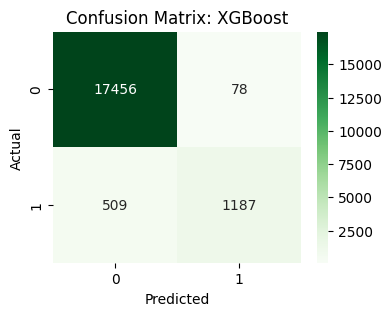

--------------------------------------------------
=== LightGBM ===


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Classification Report:
              precision    recall  f1-score   support

           0     0.9724    0.9962    0.9841     17534
           1     0.9471    0.7075    0.8100      1696

    accuracy                         0.9707     19230
   macro avg     0.9598    0.8519    0.8971     19230
weighted avg     0.9702    0.9707    0.9688     19230



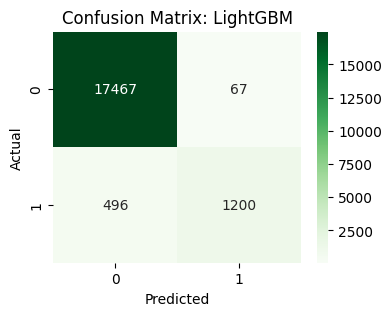

--------------------------------------------------
=== CatBoost ===
Classification Report:
              precision    recall  f1-score   support

           0     0.9722    0.9949    0.9835     17534
           1     0.9308    0.7064    0.8032      1696

    accuracy                         0.9695     19230
   macro avg     0.9515    0.8506    0.8933     19230
weighted avg     0.9686    0.9695    0.9676     19230



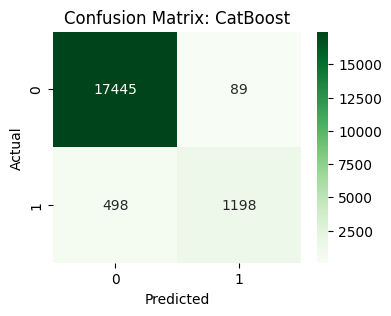

--------------------------------------------------


In [49]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

boosting_models = {
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss'),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0)
}

for name, model in boosting_models.items():
    print(f"=== {name} ===")
    # Навчання на збалансованому train або прямому train
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)

    print("Classification Report:")
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    print("-" * 50)

**Висновок:** Градієнтний бустинг над деревами рішень (XGBoost, LightGBM, CatBoost) показує вищу точність (precision) при високому рівні recall, що призводить до загального зростання $F_1$-score порівняно з лінійними моделями та SVC завдяки автоматичному виявленню нелінійних залежностей та взаємодій ознак.